# Solving Wordle with Search: Greedy vs DFS vs Minimax (α-β)
**KKA Midterm Project** — Tubagus Muhamad Afif

## 1. Problem formulation
Wordle: guess a hidden 5-letter word in at most **6 guesses**. After each guess, every letter gets a colour:
🟩 right letter, right place · 🟨 letter is in the word, wrong place · ⬜ letter not in the word (respecting duplicate counts).

We model Wordle as a **search problem**:

| Element | Definition |
|---|---|
| **State** | $S$ = set of answers still consistent with all feedback so far (start: all 2,309 answers) |
| **Action** | a guess $g$ from the 12,953 allowed words |
| **Transition** | feedback pattern $p(g, a) \in \{0..242\}$ ($3^5$ patterns) splits $S$ into buckets; next state $S' = \{a \in S : p(g,a) = p_{\text{observed}}\}$ |
| **Goal test** | pattern = 🟩🟩🟩🟩🟩 (code 242) |
| **Path cost** | 1 per guess → minimise number of guesses |

The difficulty: the agent does **not** know which feedback it will get, so each guess branches into up to 243 outcomes (an **AND-OR** search space).

## 2. Three algorithms compared
| Algorithm | Category (lecture) | How it treats unknown feedback | Optimises |
|---|---|---|---|
| **Greedy (max-entropy)** | Informed / greedy best-first | Looks only one step ahead | Expected information gained *now* |
| **DFS (depth-limited AND-OR)** | Uninformed search | Must succeed for **every** feedback branch within the remaining turns | First plan that is *guaranteed* to win within 6 (satisficing, not optimal) |
| **Minimax + α-β pruning** | Adversarial search | Feedback is chosen by an **adversary** (worst case) | Worst-case number of guesses |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import math, time, os, urllib.request
from collections import Counter
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
DATA_DIR = 'data'

## 3. Dataset
* `answers.txt` — 2,309 possible Wordle answers (NYT list)
* `allowed_guesses.txt` — 12,953 words accepted as guesses

Source: the word lists used in 3Blue1Brown's Wordle analysis (`github.com/3b1b/videos`, `_2022/wordle/data`). If the files are missing, the cell below downloads them.

In [2]:
SRC = 'https://raw.githubusercontent.com/3b1b/videos/master/_2022/wordle/data/'
FILES = {'answers.txt': 'possible_words.txt', 'allowed_guesses.txt': 'allowed_words.txt'}
os.makedirs(DATA_DIR, exist_ok=True)
for local, remote in FILES.items():
    path = os.path.join(DATA_DIR, local)
    if not os.path.exists(path):
        print('downloading', remote); urllib.request.urlretrieve(SRC + remote, path)

def load(name):
    with open(os.path.join(DATA_DIR, name)) as f:
        return [w.strip().lower() for w in f if len(w.strip()) == 5]

ANSWERS = load('answers.txt')
GUESSES = sorted(set(load('allowed_guesses.txt')) | set(ANSWERS))   # every answer is also a legal guess
G_INDEX = {w: i for i, w in enumerate(GUESSES)}
ANS_AS_GUESS = np.array([G_INDEX[w] for w in ANSWERS])            # answer index -> guess index
NA, NG = len(ANSWERS), len(GUESSES)
print(f'{NA} answers, {NG} allowed guesses')

2309 answers, 12953 allowed guesses


## 4. Feedback function
Pattern encoded in base 3: ⬜=0, 🟨=1, 🟩=2, so position $i$ contributes $c_i \cdot 3^i$; 🟩🟩🟩🟩🟩 = 242.
Duplicate letters: greens are assigned first, then yellows only while the answer still has unused copies of that letter.

In [3]:
ALL_GREEN = 242

def feedback(guess, answer):
    res, remaining = [0]*5, Counter()
    for i in range(5):
        if guess[i] == answer[i]: res[i] = 2
        else: remaining[answer[i]] += 1
    for i in range(5):
        if res[i] == 0 and remaining[guess[i]] > 0:
            res[i] = 1; remaining[guess[i]] -= 1
    return sum(c * 3**i for i, c in enumerate(res))

def decode(p):
    return ''.join('⬜🟨🟩'[(p // 3**i) % 3] for i in range(5))

# unit tests, including the duplicate-letter edge cases
assert decode(feedback('speed', 'abide')) == '⬜⬜🟨⬜🟨'
assert decode(feedback('eerie', 'there')) == '🟨⬜🟨⬜🟩'
assert decode(feedback('llama', 'hello')) == '🟨🟨⬜⬜⬜'
assert feedback('crane', 'crane') == ALL_GREEN
for g, a in [('speed', 'abide'), ('eerie', 'there'), ('llama', 'hello')]:
    print(g, '->', a, decode(feedback(g, a)))

speed -> abide ⬜⬜🟨⬜🟨
eerie -> there 🟨⬜🟨⬜🟩
llama -> hello 🟨🟨⬜⬜⬜


## 5. Pre-computed pattern matrix
Calling `feedback()` millions of times in Python is slow, so we pre-compute `P[g, a]` for every (guess, answer) pair
(12,953 × 2,309 ≈ 30M entries, `uint8`, ≈ 30 MB) with vectorised NumPy and cache it to disk.
Every search step afterwards becomes an array lookup.

In [4]:
def build_pattern_matrix(guesses, answers, chunk=400):
    G = np.array([[ord(c) - 97 for c in w] for w in guesses], dtype=np.int8)
    A = np.array([[ord(c) - 97 for c in w] for w in answers], dtype=np.int8)
    out = np.zeros((len(G), len(A)), dtype=np.uint8)
    pw = np.array([1, 3, 9, 27, 81], dtype=np.uint8); ar = np.arange(len(A))
    for s in range(0, len(G), chunk):
        g = G[s:s + chunk]; rows = np.arange(len(g))[:, None]
        green = g[:, None, :] == A[None, :, :]
        cnt = np.zeros((len(g), len(A), 26), dtype=np.int8)       # unused answer letters
        for i in range(5):
            cnt[:, ar, A[:, i]] += (~green[:, :, i]).astype(np.int8)
        pat = np.zeros((len(g), len(A)), dtype=np.uint8)
        for i in range(5):
            l = g[:, i].astype(np.intp)[:, None]
            yellow = (~green[:, :, i]) & (cnt[rows, ar[None, :], l] > 0)
            cnt[rows, ar[None, :], l] -= yellow.astype(np.int8)
            pat += np.where(green[:, :, i], 2, yellow.astype(np.uint8)).astype(np.uint8) * pw[i]
        out[s:s + chunk] = pat
    return out

CACHE = os.path.join(DATA_DIR, 'pattern_matrix.npy')
if os.path.exists(CACHE) and np.load(CACHE, mmap_mode='r').shape == (NG, NA):
    P = np.load(CACHE)
else:
    t = time.time(); P = build_pattern_matrix(GUESSES, ANSWERS); np.save(CACHE, P)
    print(f'built in {time.time() - t:.1f}s')

# verify the vectorised matrix against the reference function
rng = np.random.default_rng(0)
for _ in range(5000):
    gi, ai = rng.integers(NG), rng.integers(NA)
    assert P[gi, ai] == feedback(GUESSES[gi], ANSWERS[ai])
print('pattern matrix', P.shape, 'verified ✔')

pattern matrix (12953, 2309) verified ✔


## 6. Shared helpers
* `buckets(g, S)` — partition of state $S$ by feedback of guess $g$ (the children of an AND node)
* `pattern_counts(S)` — bucket sizes for **all** guesses at once, used by Greedy and Minimax move ordering
* `Stats` — counts **guess evaluations** (one guess scored against one state), so effort is comparable across algorithms

In [5]:
class Stats:
    def __init__(self): self.evals = 0

def buckets(g, S):
    pats = P[g, S]
    order = np.argsort(pats, kind='stable'); ps = pats[order]
    cuts = np.flatnonzero(np.diff(ps)) + 1
    return {int(grp[0]): S[o] for grp, o in zip(np.split(ps, cuts), np.split(order, cuts))}

def pattern_counts(S):
    # cnt[g, p] = how many answers in S give pattern p for guess g
    off = P[:, S].astype(np.int64) + np.arange(NG)[:, None] * 243
    return np.bincount(off.ravel(), minlength=NG * 243).reshape(NG, 243)

def candidate_mask(S):
    m = np.zeros(NG, bool); m[ANS_AS_GUESS[S]] = True; return m

## 7. Algorithm 1 — Greedy (maximum entropy)
At each turn pick the guess whose feedback gives the most **expected information**:
$$H(g) = -\sum_{p} \frac{|S_p|}{|S|}\log_2\frac{|S_p|}{|S|}$$
It is **greedy**: it maximises information for the current step only and never looks further ahead.
Ties are broken in favour of words that could still be the answer (a chance to win immediately).

In [6]:
def greedy_choose(S, turn, st):
    if len(S) <= 2:                       # just guess a candidate
        st.evals += 1; return int(ANS_AS_GUESS[S[0]])
    st.evals += NG
    p = pattern_counts(S) / len(S)
    with np.errstate(divide='ignore', invalid='ignore'):
        H = -np.where(p > 0, p * np.log2(p), 0).sum(1)
    H = H + candidate_mask(S) * 1e-6      # tie-break
    return int(np.argmax(H))

## 8. Algorithm 2 — Depth-limited DFS on the AND-OR tree
Uninformed search (AIMA ch.4 AND-OR search, depth-first):
* **OR node** (our turn): try guesses one by one in a **fixed alphabetical order**, with no heuristic.
* **AND node** (feedback): a guess is accepted only if **every** possible feedback bucket can itself be solved within the remaining depth.
* Depth limit = guesses left (6 − turn), so a returned plan **guarantees a win within 6 guesses** (*complete* for this limit).
* DFS returns the **first** plan that works, not the best one, so it is not optimal in number of guesses.
* To keep the branching factor manageable, uninformed DFS only considers words still in $S$ (like hard mode).
  A memo table stores sub-states already proven solvable or unsolvable.

In [7]:
def dfs_plan(S, depth, st, memo):
    key = (S.tobytes(), depth)
    if key in memo: return memo[key]
    if depth == 0:
        memo[key] = None; return None
    for a in S:                                   # OR node: alphabetical, uninformed
        g = int(ANS_AS_GUESS[a]); st.evals += 1
        ok = True
        for p, b in buckets(g, S).items():        # AND node: every feedback must be solvable
            if p == ALL_GREEN: continue
            if dfs_plan(b, depth - 1, st, memo) is None:
                ok = False; break                 # backtrack
        if ok:
            memo[key] = g; return g
    memo[key] = None; return None

def dfs_choose(S, turn, st, max_guesses=6):
    g = dfs_plan(S, max_guesses - turn, st, {})
    return g if g is not None else int(ANS_AS_GUESS[S[0]])   # fallback if no guaranteed plan exists

## 9. Algorithm 3 — Minimax with α-β pruning
Wordle as a two-player game:
* **MIN** = solver, picks a guess to *minimise* the number of guesses;
* **MAX** = adversary, picks the feedback pattern (any non-empty bucket) to *maximise* it.

$$V(S) = \begin{cases} 1 & |S| = 1 \\ \min_g \max_{p \neq 242} \big(1 + V(S_p)\big) & \text{otherwise}\end{cases}$$

Practical choices:
* **Depth-limited**, with leaf evaluation $h(n) = \max(2,\; 1 + \tfrac{\log_2 n}{3})$ for $n>1$ ($h(1)=1$), an estimate of worst-case guesses left.
* **Move ordering**: guesses are ranked by their 1-ply minimax value (vectorised over all 12,953 words); only the top-$K$ are expanded.
* **α-β pruning**: inside the adversary's loop, buckets are visited largest-first; as soon as one branch is ≥ the solver's best value so far, that guess is cut off.

In [8]:
def h(n): return 1.0 if n == 1 else max(2.0, 1 + math.log2(n) / 3)
H_TABLE = np.array([0.0] + [h(n) for n in range(1, NA + 1)])

def one_ply_values(S, st):
    st.evals += NG
    cnt = pattern_counts(S); cnt[:, ALL_GREEN] = 0
    maxb = cnt.max(1)                        # adversary's best reply = largest bucket
    return np.where(maxb == 0, 1.0, 1.0 + H_TABLE[maxb])

def minimax(S, depth, beta, st, K):
    # returns (worst-case guesses, best guess); solver = MIN, feedback = MAX
    if len(S) == 1: return 1.0, int(ANS_AS_GUESS[S[0]])
    v1 = one_ply_values(S, st)
    order = np.lexsort((~candidate_mask(S), v1))[:K]       # move ordering
    if depth == 1: return float(v1[order[0]]), int(order[0])
    best, best_g = math.inf, int(order[0])
    for g in map(int, order):
        worst = 1.0
        for p, b in sorted(buckets(g, S).items(), key=lambda kv: -len(kv[1])):
            if p == ALL_GREEN: continue
            v, _ = minimax(b, depth - 1, best - 1, st, K)
            worst = max(worst, 1 + v)
            if worst >= best or worst >= beta:   # α-β cut-off
                break
        if worst < best: best, best_g = worst, g
        if best <= 2.0: break                    # can't beat 2 when |S| > 1
    return best, best_g

def make_minimax_choose(depth=2, K=20):
    return lambda S, turn, st: minimax(S, depth, math.inf, st, K)[1]

## 10. Game environments
* **Normal Wordle** — the hidden answer is fixed in advance.
* **Adversarial Wordle** (*Absurdle*-style) — there is no fixed answer; after each guess the environment keeps the **largest** consistent bucket, so it dodges the solver as long as possible.

Every solver is deterministic, so decisions are cached per state: games that reach the same state reuse the decision.

In [9]:
def cached(choose_fn):
    cache = {}
    def choose(S, turn, st):
        key = S.tobytes()
        if key not in cache: cache[key] = choose_fn(S, turn, st)
        return cache[key]
    return choose

def play(choose, answer, max_turns=12, st=None):
    st = st or Stats(); S = np.arange(NA); history = []
    for turn in range(max_turns):
        g = choose(S, turn, st); p = int(P[g, answer]); history.append((GUESSES[g], p, len(S)))
        if p == ALL_GREEN: return turn + 1, history
        S = S[P[g, S] == p]
    return max_turns + 1, history

def play_adversarial(choose, max_turns=15):
    st = Stats(); S = np.arange(NA); history = []
    for turn in range(max_turns):
        g = choose(S, turn, st); bk = buckets(g, S)
        if list(bk) == [ALL_GREEN]:
            history.append((GUESSES[g], ALL_GREEN, len(S))); return turn + 1, history, st.evals
        p = max((q for q in bk if q != ALL_GREEN), key=lambda q: (len(bk[q]), -q))
        history.append((GUESSES[g], p, len(S))); S = bk[p]
    return max_turns + 1, history, st.evals

SOLVERS = {
    'Greedy (entropy)': lambda: cached(greedy_choose),
    'DFS (AND-OR)':     lambda: cached(dfs_choose),
    'Minimax α-β':      lambda: cached(make_minimax_choose(depth=2, K=20)),
}

## 11. Demo — the three solvers on the same word

In [10]:
def show(name, history):
    print(f'{name}')
    for word, p, n in history:
        print(f'   {word.upper()}  {decode(p)}   (candidates before guess: {n})')

DEMO_WORD = 'crimp'           # change me
for name, make in SOLVERS.items():
    n, hist = play(make(), ANSWERS.index(DEMO_WORD))
    show(f'{name}: solved in {n}', hist); print()

Greedy (entropy): solved in 3
   SOARE  ⬜⬜⬜🟨⬜   (candidates before guess: 2309)
   GLINT  ⬜⬜🟩⬜⬜   (candidates before guess: 57)
   CRIMP  🟩🟩🟩🟩🟩   (candidates before guess: 5)



DFS (AND-OR): solved in 4
   ABACK  ⬜⬜⬜🟨⬜   (candidates before guess: 2309)
   CELLO  🟩⬜⬜⬜⬜   (candidates before guess: 147)
   CHIRP  🟩⬜🟩🟨🟩   (candidates before guess: 14)
   CRIMP  🟩🟩🟩🟩🟩   (candidates before guess: 2)



Minimax α-β: solved in 4
   ALOES  ⬜⬜⬜⬜⬜   (candidates before guess: 2309)
   RINDY  🟨🟨⬜⬜⬜   (candidates before guess: 161)
   CHAPT  🟩⬜⬜🟨⬜   (candidates before guess: 9)
   CRIMP  🟩🟩🟩🟩🟩   (candidates before guess: 1)



## 12. Experiment 1 — every answer in normal Wordle
Each solver plays all 2,309 answers. Metrics: mean / std / worst number of guesses, failure rate (> 6 guesses),
guess distribution, total runtime, and search effort (guess evaluations).

In [11]:
results, dist = [], {}
for name, make in SOLVERS.items():
    choose, st = make(), Stats(); t0 = time.time()
    n = np.array([play(choose, a, st=st)[0] for a in range(NA)])
    elapsed = time.time() - t0
    dist[name] = n
    results.append({'Solver': name, 'Mean guesses': n.mean(), 'Std': n.std(), 'Worst case': n.max(),
                    'Win ≤6 (%)': 100 * (n <= 6).mean(), 'Fails (>6)': int((n > 6).sum()),
                    'Total time (s)': elapsed, 'Guess evals': st.evals,
                    'First guess': GUESSES[choose(np.arange(NA), 0, Stats())].upper()})
df = pd.DataFrame(results).set_index('Solver')
df.style.format({'Mean guesses': '{:.3f}', 'Std': '{:.3f}', 'Win ≤6 (%)': '{:.2f}',
                 'Total time (s)': '{:.1f}', 'Guess evals': '{:,}'})

,Mean guesses,Std,Worst case,Win ≤6 (%),Fails (>6),Total time (s),Guess evals,First guess
Solver,,,,,,,,
Greedy (entropy),3.464,0.587,6,100.00,0,17.2,"4,108,263",SOARE
DFS (AND-OR),4.217,0.941,6,100.00,0,2.7,"92,623",ABACK
Minimax α-β,3.660,0.633,5,100.00,0,11.9,"37,783,901",ALOES


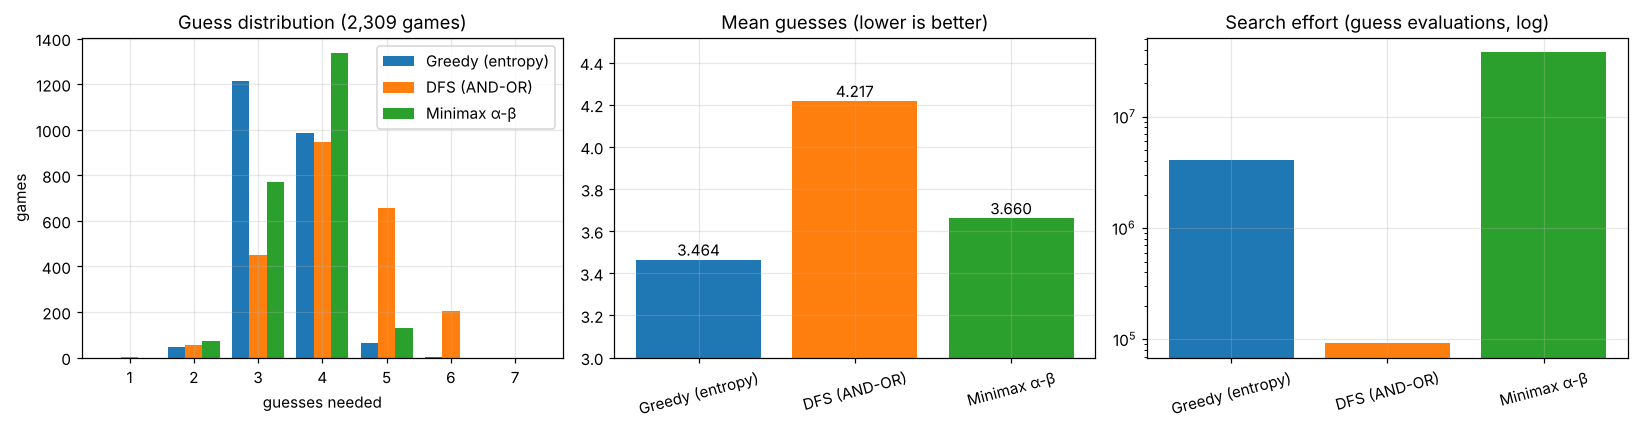

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
bins = np.arange(1, 9); w = 0.27
for k, (name, n) in enumerate(dist.items()):
    counts = [(n == b).sum() for b in bins[:-1]]
    ax[0].bar(bins[:-1] + (k - 1) * w, counts, width=w, label=name)
ax[0].set(title='Guess distribution (2,309 games)', xlabel='guesses needed', ylabel='games'); ax[0].legend()
ax[1].bar(df.index, df['Mean guesses'], color=['C0', 'C1', 'C2'])
ax[1].set(title='Mean guesses (lower is better)', ylim=(3, df['Mean guesses'].max() + .3))
for i, v in enumerate(df['Mean guesses']): ax[1].text(i, v + .02, f'{v:.3f}', ha='center')
ax[2].bar(df.index, df['Guess evals'], color=['C0', 'C1', 'C2']); ax[2].set_yscale('log')
ax[2].set(title='Search effort (guess evaluations, log)')
for a in ax[1:]: a.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

## 13. Experiment 2 — adversarial Wordle (worst case)
The environment always keeps the largest bucket. This is the setting Minimax is designed for.

In [13]:
adv = []
for name, make in SOLVERS.items():
    n, hist, ev = play_adversarial(make())
    show(f'{name}: {n} guesses', hist); print()
    adv.append({'Solver': name, 'Guesses vs adversary': n, 'Guess evals': ev})
pd.DataFrame(adv).set_index('Solver')

Greedy (entropy): 5 guesses
   SOARE  ⬜⬜⬜⬜⬜   (candidates before guess: 2309)
   CLINT  ⬜⬜⬜⬜⬜   (candidates before guess: 182)
   DUMPY  ⬜🟩⬜⬜🟩   (candidates before guess: 15)
   BUGGY  ⬜🟩⬜⬜🟩   (candidates before guess: 2)
   FUZZY  🟩🟩🟩🟩🟩   (candidates before guess: 1)



DFS (AND-OR): 6 guesses
   ABACK  ⬜⬜⬜⬜⬜   (candidates before guess: 2309)
   DEPOT  ⬜🟨⬜⬜⬜   (candidates before guess: 925)
   ELEGY  🟨⬜⬜⬜⬜   (candidates before guess: 82)
   MINER  ⬜🟩⬜🟩🟩   (candidates before guess: 24)
   RISER  ⬜🟩⬜🟩🟩   (candidates before guess: 4)
   FIXER  🟩🟩🟩🟩🟩   (candidates before guess: 1)



Minimax α-β: 5 guesses
   ALOES  ⬜⬜⬜🟨⬜   (candidates before guess: 2309)
   NITRE  ⬜⬜⬜🟨🟩   (candidates before guess: 172)
   CREME  ⬜🟨🟨⬜🟩   (candidates before guess: 11)
   VERGE  🟨🟩🟨⬜🟩   (candidates before guess: 3)
   REVUE  🟩🟩🟩🟩🟩   (candidates before guess: 1)



,Guesses vs adversary,Guess evals
Solver,,
Greedy (entropy),5,38861
DFS (AND-OR),6,60794
Minimax α-β,5,4896234


## 14. Experiment 3 — ablation on Minimax depth and branching $K$
How do search depth and the number of expanded moves change quality and cost?

In [14]:
abl = []
for depth, K in [(1, 1), (2, 5), (2, 10), (2, 20), (3, 8)]:
    choose, st = cached(make_minimax_choose(depth, K)), Stats(); t0 = time.time()
    n = np.array([play(choose, a, st=st)[0] for a in range(NA)])
    adv_n = play_adversarial(cached(make_minimax_choose(depth, K)))[0]
    abl.append({'depth': depth, 'K': K, 'Mean guesses': round(n.mean(), 3), 'Worst case': n.max(),
                'Games >5': int((n > 5).sum()), 'Adversarial': adv_n,
                'Time (s)': round(time.time() - t0, 1), 'Guess evals': st.evals})
pd.DataFrame(abl)

,depth,K,Mean guesses,Worst case,Games >5,Adversarial,Time (s),Guess evals
0,1,1,3.690,8,44,5,3.2,7758847
1,2,5,3.644,7,4,5,8.5,21670369
2,2,10,3.660,6,4,5,11.2,27628749
3,2,20,3.660,5,0,5,14.8,37783901
4,3,8,3.647,6,6,5,23.3,66435937


## 15. Discussion notes (for Chapter 3)
Use the tables above; key points to discuss:
1. **Greedy (entropy)** has the best average. Information gain is a strong heuristic for Wordle,
   because the feedback is effectively random, not adversarial. Compare with the proven optimum of ≈ 3.42 guesses (Alex Selby, 2022).
2. **DFS** always wins within 6 (it is complete for the depth limit) and needs very little computation, but it is uninformed:
   alphabetical order gives a poor opening (`ABACK`) and a much higher mean. It shows the gap between *satisficing* and *optimising*.
3. **Minimax α-β** optimises the worst case. In normal Wordle it is slightly worse on average than Greedy,
   because it plays "safe" against an adversary that doesn't exist, but its **worst case is better** (no game needs 6 guesses at depth 2, K = 20).
   α-β pruning plus move ordering keeps it fast despite the 243-way branching. The ablation shows K matters more than depth.
4. **Trade-off:** the "best" algorithm depends on the assumed environment (stochastic vs adversarial) and on the compute budget.

Possible extensions: hard mode; Expectimax (chance nodes instead of an adversary); a better DFS move order (iterative deepening).